# Learning P(success) from synthetic trajectories

This notebook trains a small neural network to predict the probability that a trajectory reaches a target pose $(x, y, \theta)$.

1. **Data** – real target conditions plus synthetic trajectories (`data/results_xy.xlsx`).
2. **Training** – a 2-layer `tanh` MLP with a sigmoid output, trained on synthetic data only and tested on the held-out real conditions.
3. **Trained model** – loads the saved model `nn_model_synthetic_trajectories.keras`.
4. **Figure** – predicted P(success) over $(x, y)$ at $\theta = -\pi/4$ (`fig_contour_npi4`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from sklearn.model_selection import train_test_split
import tensorflow as tf

DATA_PATH  = "data/results_xy.xlsx"
MODEL_PATH = "nn_model_synthetic_trajectories.keras"

## 1. Data

The Excel file has two sheets: `real_targets_summary` (measured conditions) and `synthetic_targets_summary` (synthetic trajectories generated between real targets).
Probabilities are Laplace-smoothed, $p = (k+1)/(n+2)$, so they never hit exactly 0 or 1.

In [2]:
xl = pd.ExcelFile(DATA_PATH)

real  = xl.parse("real_targets_summary")
synth = xl.parse("synthetic_targets_summary")

# standardise column names
real  = real[["x_target", "y_target", "theta_target_deg", "n_trials", "n_success", "probability"]]
synth = synth[["x_target", "y_target", "theta_target_deg", "n_synth_trajectories", "n_success", "probability"]]
synth = synth.rename(columns={"n_synth_trajectories": "n_trials"})

# Laplace smoothing: p_smooth = (k + 1) / (n + 2)
for df in [real, synth]:
    df["p_smooth"] = (df["n_success"] + 1) / (df["n_trials"] + 2)

all_data = pd.concat([real, synth], ignore_index=True)
all_data["theta_rad"] = np.deg2rad(all_data["theta_target_deg"])

print(f"Real conditions     : {len(real)}")
print(f"Synthetic conditions: {len(synth)}")
print(f"Total               : {len(all_data)}")
print(f"p_smooth range      : [{all_data.p_smooth.min():.3f}, {all_data.p_smooth.max():.3f}]")

Real conditions     : 26
Synthetic conditions: 102
Total               : 128
p_smooth range      : [0.071, 0.923]


## 2. Training

Inputs are $(x, y, \theta)$, normalised. The network is trained on the synthetic data (80/20 train/validation split); the real conditions are held out as the test set.

In [4]:
x_mean, x_std = all_data.x_target.mean(), all_data.x_target.std()
y_mean, y_std = all_data.y_target.mean(), all_data.y_target.std()

def featurize(x, y, theta):
    return np.column_stack([
        (np.asarray(x, float) - x_mean) / x_std,
        (np.asarray(y, float) - y_mean) / y_std,
        np.asarray(theta, float) / (np.pi / 4),
    ]).astype(np.float32)

# test set = real conditions (held out)
X_test = featurize(real.x_target, real.y_target, np.deg2rad(real.theta_target_deg))
y_test = real.p_smooth.values.astype(np.float32)

# train / validation = synthetic data only
X_synth = featurize(synth.x_target, synth.y_target, np.deg2rad(synth.theta_target_deg))
y_synth = synth.p_smooth.values.astype(np.float32)
X_train, X_val, y_train, y_val = train_test_split(X_synth, y_synth, test_size=0.2, random_state=42)

print(f"\nTrain : {len(X_train)} rows (synthetic)")
print(f"Val   : {len(X_val)}  rows (synthetic)")
print(f"Test  : {len(X_test)}  rows (real — held out)")


Train : 81 rows (synthetic)
Val   : 21  rows (synthetic)
Test  : 26  rows (real — held out)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)


 Epoch   Train RMSE   Val RMSE
     0    0.26156     0.29629
   500    0.14586     0.19148
  1000    0.12505     0.15872
  1500    0.12616     0.14255
  2000    0.10406     0.13683
  2500    0.09564     0.13511
  3000    0.11108     0.13633
  3500    0.08507     0.13475
  4000    0.08748     0.13489
  4500    0.10169     0.13440
  5000    0.10880     0.13533
  5500    0.09278     0.13541
  6000    0.07872     0.13544
  6500    0.08492     0.13521

FINAL TEST (26 real conditions)
Test RMSE : 0.12530
Test MAE  : 0.10013
Test Max  : 0.27972


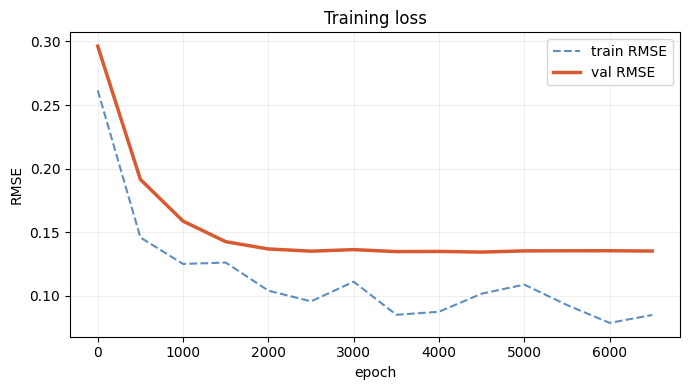

In [5]:
def init_model(dim=3, hidden=32, n_layers=2):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(dim,))])
    for _ in range(n_layers):
        model.add(tf.keras.layers.Dense(hidden, activation="tanh",
                                        kernel_regularizer=tf.keras.regularizers.l2(1e-3)))
        model.add(tf.keras.layers.Dropout(0.1))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    return model

model = init_model()
model.summary()

def loss_fn(X, y, model, training=False):
    y_pred = model(X, training=training)
    y = tf.reshape(y, tf.shape(y_pred))
    return tf.reduce_mean(tf.math.squared_difference(y, y_pred))

@tf.function
def compute_grad(X, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(X, y, model, training=True)
    return loss, tape.gradient(loss, model.trainable_variables)

lr = tf.keras.optimizers.schedules.PiecewiseConstantDecay([2500, 5000], [1e-3, 1e-4, 1e-5])
optimizer = tf.keras.optimizers.Adam(learning_rate=lr, epsilon=1e-8)

num_epochs   = 7000
batch_size   = min(64, len(X_train))
log_interval = 500

ht, hv, he = [], [], []
print("\n Epoch   Train RMSE   Val RMSE")
for i in range(num_epochs):
    idx = np.random.choice(len(X_train), batch_size, replace=False)
    loss, grad = compute_grad(tf.gather(X_train, idx), tf.gather(y_train, idx))
    optimizer.apply_gradients(zip(grad, model.trainable_variables))

    if i % log_interval == 0:
        vl = loss_fn(X_val, y_val, model)
        ht.append(loss.numpy()); hv.append(vl.numpy()); he.append(i)
        print(f" {i:5d}    {np.sqrt(loss.numpy()):.5f}     {np.sqrt(vl.numpy()):.5f}")

# ---- test on the held-out real conditions ----
print("\n" + "=" * 55)
print(f"FINAL TEST ({len(X_test)} real conditions)")
print("=" * 55)
y_pred_test = model(X_test, training=False).numpy().flatten()
abs_err = np.abs(y_pred_test - y_test)
print(f"Test RMSE : {np.sqrt(np.mean(abs_err**2)):.5f}")
print(f"Test MAE  : {abs_err.mean():.5f}")
print(f"Test Max  : {abs_err.max():.5f}")

# ---- loss curve ----
plt.figure(figsize=(7, 4))
plt.plot(he, np.sqrt(ht), color="#185FA5", lw=1.5, ls="--", alpha=0.7, label="train RMSE")
plt.plot(he, np.sqrt(hv), color="#D85A30", lw=2.5, label="val RMSE")
plt.xlabel("epoch"); plt.ylabel("RMSE")
plt.title("Training loss"); plt.legend(); plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Uncomment to overwrite the saved model with this run:
# model.save(MODEL_PATH)

## 3. Trained model

Load the model used for the results below (training above is stochastic, so a fresh run will differ slightly).

In [6]:
model = tf.keras.models.load_model(MODEL_PATH)
print("Model loaded.")
model.summary()

# input normalisation used when this model was trained
x_mean, x_std = 6.0, 2.449
y_mean, y_std = 0.0, 2.449

Model loaded.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Figure: predicted P(success) at $\theta = -\pi/4$

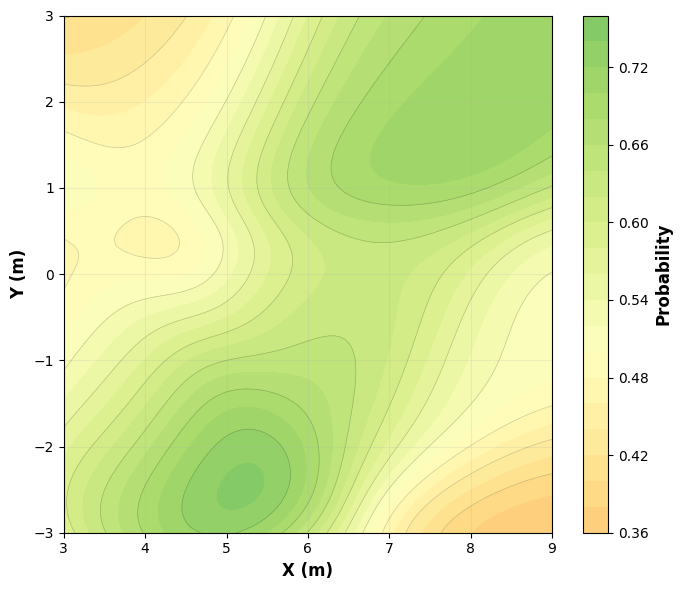

In [7]:
theta_plot = -np.pi / 4

xx, yy = np.meshgrid(np.linspace(3, 9, 100), np.linspace(-3, 3, 100))
X_grid = featurize(xx.ravel(), yy.ravel(), np.full(xx.size, theta_plot))
p_nn   = model(X_grid, training=False).numpy().reshape(xx.shape)

fig_contour_npi4, ax = plt.subplots(figsize=(7, 6))

c = ax.contourf(xx, yy, p_nn, levels=20, cmap="RdYlGn", vmin=0, vmax=1)
cbar = plt.colorbar(c, ax=ax)
cbar.set_label("Probability", fontsize=12, fontweight="bold")
ax.contour(xx, yy, p_nn, levels=10, colors="black", alpha=0.2, linewidths=0.5)

ax.set_xlabel("X (m)", fontsize=12, fontweight="bold")
ax.set_ylabel("Y (m)", fontsize=12, fontweight="bold")
ax.set_xlim(3, 9)
ax.set_ylim(-3, 3)
ax.grid(alpha=0.2)

plt.tight_layout()
fig_contour_npi4.savefig("fig_contour_npi4.pdf", dpi=150, bbox_inches="tight")
fig_contour_npi4.savefig("fig_contour_npi4.png", dpi=150, bbox_inches="tight")
plt.show()